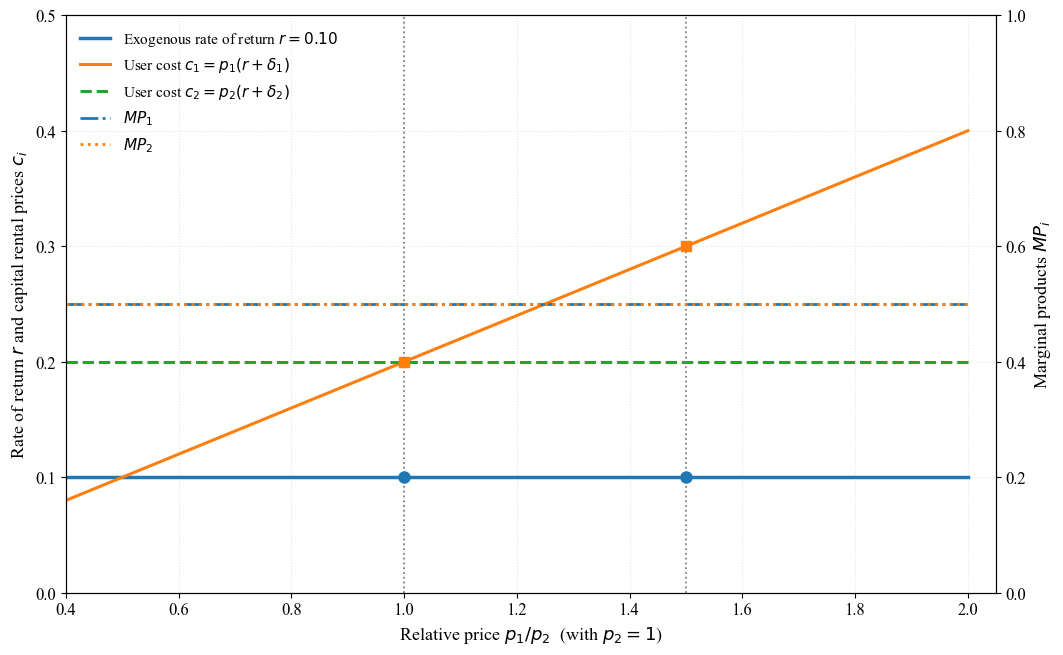

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ============================
# 基本设置
# ============================
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['font.family'] = ['Times New Roman', 'DejaVu Serif', 'serif']

# ============================================================
# Config：所有可调节参数集中在此，方便查看与修改
# ============================================================
Config = {
    # ---------- 模型参数 ----------
    'K1'      : 100.0,          # 部门1的资本存量（固定）
    'K2'      : 100.0,          # 部门2的资本存量（固定）
    'p2'      : 1.0,            # 部门2的价格（计价物，固定为1）
    'r'       : 0.10,           # 外生利润率（恒定）
    'delta1'  : 0.10,           # 部门1的折旧率
    'delta2'  : 0.10,           # 部门2的折旧率
    'pi1'     : 0.0,            # 部门1的预期通胀率
    'pi2'     : 0.0,            # 部门2的预期通胀率

    # ---------- 相对价格取值区间 ----------
    'p1_min'  : 0.4,            # p1/p2 的最小值
    'p1_max'  : 2.0,            # p1/p2 的最大值
    'n_p1'    : 300,            # 采样点数

    # ---------- 图形尺寸与坐标轴范围 ----------
    'fig_w'        : 12.0,      # 画布宽度（英寸）
    'fig_h'        : 7.5,       # 画布高度（英寸）
    'xlim'         : (0.4, 2.05),   # 横轴范围
    'ylim_left'    : (0.0, 0.50),   # 左轴（r 与 c_i）范围
    'ylim_right'   : (0.0, 1.0),    # 右轴（MP_i）范围
    'labelsize'    : 12,        # 坐标轴刻度字号
    'axlabel_size' : 13,        # 坐标轴标题字号

    # ---------- 参考点 ----------
    'p0'      : 1.0,            # 初始相对价格
    'p_new'   : 1.5,            # 变化后的相对价格
    'vline_color' : 'gray',     # 参考竖线颜色
    'vline_ls'    : ':',        # 参考竖线线型
    'vline_lw'    : 1.3,        # 参考竖线线宽

    # ---------- 图例 ----------
    'legend_loc'   : 'upper left',  # 图例位置
    'legend_size'  : 11,            # 图例字号

    # ---------- 保存 ----------
    'save'    : True,                       # 是否保存图片
    'save_name' : 'exogenous_rental.svg',  # 文件名
    'save_dpi'  : 300,                      # 若保存为 png 时的分辨率
}

# ============================
# 从 Config 解包参数
# ============================
K1, K2 = Config['K1'], Config['K2']
p2     = Config['p2']
r_val  = Config['r']
delta1, delta2 = Config['delta1'], Config['delta2']
pi1, pi2       = Config['pi1'], Config['pi2']

p1 = np.linspace(Config['p1_min'], Config['p1_max'], Config['n_p1'])

# 外生利润率
r = r_val * np.ones_like(p1)

# 资本价值和内生资本收入
V = p1 * K1 + p2 * K2
Pi_K = r * V          # 资本收入随 V 内生调整

# 使用者成本
c1 = p1 * (r + delta1 - pi1)   # = 0.20 p1
c2 = p2 * (r + delta2 - pi2)   # = 0.20

# 租金权重（仅计算，不画图）
RentalValue = c1 * K1 + c2 * K2
s1 = c1 * K1 / RentalValue
s2 = c2 * K2 / RentalValue

# 边际产出（常数）
MP1 = 0.5 * np.sqrt(K2 / K1) * np.ones_like(p1)
MP2 = 0.5 * np.sqrt(K1 / K2) * np.ones_like(p1)

# ============================
# 创建图形
# ============================
fig, ax1 = plt.subplots(figsize=(Config['fig_w'], Config['fig_h']))
x = p1 / p2

# 左轴曲线
ax1.plot(x, r, lw=2.5, label=r'Exogenous rate of return $r=0.10$')
ax1.plot(x, c1, lw=2.2, label=r'User cost $c_1=p_1(r+\delta_1)$')
ax1.plot(x, c2, lw=2.2, ls='--', label=r'User cost $c_2=p_2(r+\delta_2)$')
ax1.set_xlabel(r'Relative price $p_1/p_2$  (with $p_2=1$)', fontsize=Config['axlabel_size'])
ax1.set_ylabel(r'Rate of return $r$ and capital rental prices $c_i$', fontsize=Config['axlabel_size'])
ax1.set_xlim(*Config['xlim'])
ax1.set_ylim(*Config['ylim_left'])
ax1.grid(alpha=0.3, ls=':')
ax1.tick_params(labelsize=Config['labelsize'])

# 右轴曲线
ax2 = ax1.twinx()
ax2.plot(x, MP1, lw=2.0, ls='-.', label=r'$MP_1$')
ax2.plot(x, MP2, lw=2.0, ls=':',  label=r'$MP_2$')
ax2.set_ylabel(r'Marginal products $MP_i$', fontsize=Config['axlabel_size'])
ax2.set_ylim(*Config['ylim_right'])
ax2.tick_params(labelsize=Config['labelsize'])
ax2.grid(False)

# ============================
# 参考点和标记
# ============================
p0, p_new = Config['p0'], Config['p_new']
r0 = r_val
r1 = r_val
c10 = p0    * (r0 + delta1)
c20 = p2    * (r0 + delta2)
c11 = p_new * (r1 + delta1)
c21 = p2    * (r1 + delta2)

ax1.axvline(p0,    color=Config['vline_color'], ls=Config['vline_ls'], lw=Config['vline_lw'])
ax1.axvline(p_new, color=Config['vline_color'], ls=Config['vline_ls'], lw=Config['vline_lw'])
ax1.plot(p0,    r0,  'o', ms=8, color='C0')
ax1.plot(p_new, r1,  'o', ms=8, color='C0')
ax1.plot(p0,    c10, 's', ms=7, color='C1')
ax1.plot(p_new, c11, 's', ms=7, color='C1')

# ============================
# 图例、标题、保存
# ============================
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2,
           loc=Config['legend_loc'], frameon=False,
           prop={'family': 'Times New Roman', 'size': Config['legend_size']})

if Config['save']:
    plt.savefig(Config['save_name'], format='svg',
                dpi=Config['save_dpi'], bbox_inches='tight')

plt.show()

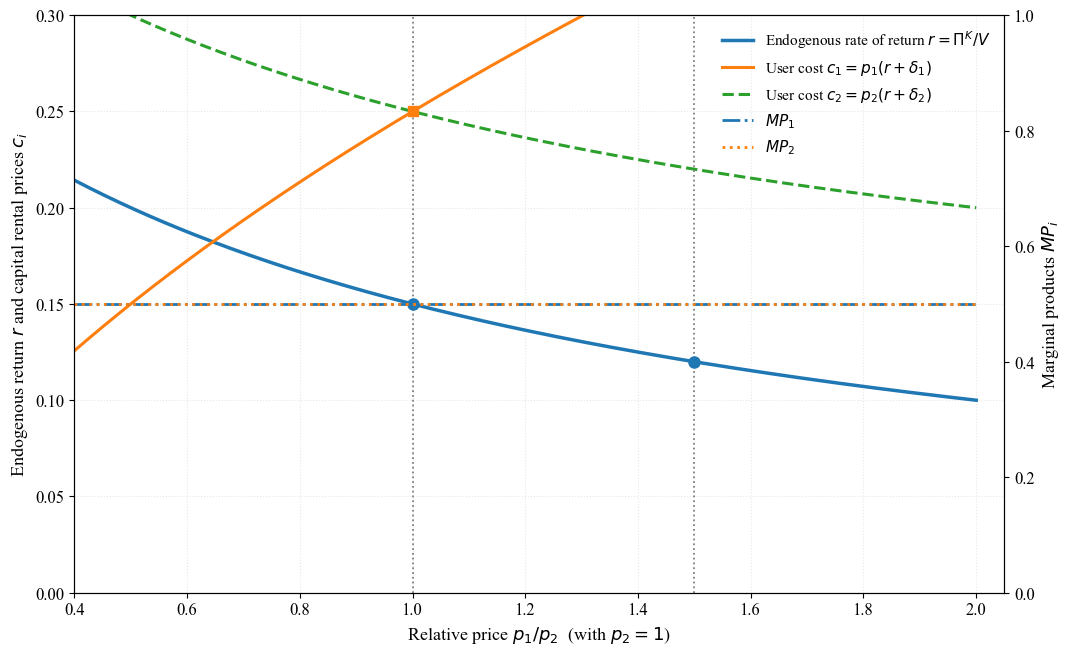

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# ============================
# 基本设置
# ============================
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['font.family'] = ['Times New Roman', 'DejaVu Serif', 'serif']

# ============================================================
# Config：所有可调节参数集中在此，方便查看与修改
# ============================================================
Config = {
    # ---------- 模型参数 ----------
    'K1'      : 100.0,          # 部门1的资本存量（固定）
    'K2'      : 100.0,          # 部门2的资本存量（固定）
    'p2'      : 1.0,            # 部门2的价格（计价物，固定为1）
    'Pi_K'    : 30.0,           # 资本收入总额 Π^K（固定）
    'delta1'  : 0.10,           # 部门1的折旧率
    'delta2'  : 0.10,           # 部门2的折旧率
    'pi1'     : 0.0,            # 部门1的预期通胀率
    'pi2'     : 0.0,            # 部门2的预期通胀率

    # ---------- 相对价格取值区间 ----------
    'p1_min'  : 0.4,            # p1/p2 的最小值
    'p1_max'  : 2.0,            # p1/p2 的最大值
    'n_p1'    : 300,            # 采样点数

    # ---------- 图形尺寸与坐标轴范围 ----------
    'fig_w'        : 12.0,      # 画布宽度（英寸）
    'fig_h'        : 7.5,       # 画布高度（英寸）
    'xlim'         : (0.4, 2.05),   # 横轴范围
    'ylim_left'    : (0.0, 0.30),   # 左轴（r 与 c_i）范围
    'ylim_right'   : (0.0, 1.0),    # 右轴（MP_i）范围
    'labelsize'    : 12,        # 坐标轴刻度字号
    'axlabel_size' : 13,        # 坐标轴标题字号

    # ---------- 参考点 ----------
    'p0'      : 1.0,            # 初始相对价格
    'p_new'   : 1.5,            # 变化后的相对价格
    'vline_color' : 'gray',     # 参考竖线颜色
    'vline_ls'    : ':',        # 参考竖线线型
    'vline_lw'    : 1.3,        # 参考竖线线宽

    # ---------- 图例 ----------
    'legend_loc'   : 'upper right',  # 图例位置
    'legend_size'  : 11,             # 图例字号

    # ---------- 保存 ----------
    'save'      : True,                                     # 是否保存图片
    'save_name' : 'endogenous_rental.svg',                  # 文件名
    'save_dpi'  : 300,                                      # 若保存为 png 时的分辨率
}

# ============================
# 从 Config 解包参数
# ============================
K1, K2 = Config['K1'], Config['K2']
p2     = Config['p2']
Pi_K   = Config['Pi_K']
delta1, delta2 = Config['delta1'], Config['delta2']
pi1, pi2       = Config['pi1'], Config['pi2']

p1 = np.linspace(Config['p1_min'], Config['p1_max'], Config['n_p1'])

# 资本价值、内生收益率、使用者成本
V  = p1 * K1 + p2 * K2
r  = Pi_K / V
c1 = p1 * (r + delta1 - pi1)
c2 = p2 * (r + delta2 - pi2)

# 租金权重（仅计算，不画图）
RentalValue = c1 * K1 + c2 * K2
s1 = c1 * K1 / RentalValue
s2 = c2 * K2 / RentalValue

# 边际产出（常数）
MP1 = 0.5 * np.sqrt(K2 / K1) * np.ones_like(p1)
MP2 = 0.5 * np.sqrt(K1 / K2) * np.ones_like(p1)

# ============================
# 创建图形
# ============================
fig, ax1 = plt.subplots(figsize=(Config['fig_w'], Config['fig_h']))
x = p1 / p2

# 左轴曲线
ax1.plot(x, r,  lw=2.5, label=r'Endogenous rate of return $r=\Pi^K/V$')
ax1.plot(x, c1, lw=2.2, label=r'User cost $c_1=p_1(r+\delta_1)$')
ax1.plot(x, c2, lw=2.2, ls='--', label=r'User cost $c_2=p_2(r+\delta_2)$')
ax1.set_xlabel(r'Relative price $p_1/p_2$  (with $p_2=1$)', fontsize=Config['axlabel_size'])
ax1.set_ylabel(r'Endogenous return $r$ and capital rental prices $c_i$', fontsize=Config['axlabel_size'])
ax1.set_xlim(*Config['xlim'])
ax1.set_ylim(*Config['ylim_left'])
ax1.grid(alpha=0.3, ls=':')
ax1.tick_params(labelsize=Config['labelsize'])

# 右轴曲线
ax2 = ax1.twinx()
ax2.plot(x, MP1, lw=2.0, ls='-.', label=r'$MP_1$')
ax2.plot(x, MP2, lw=2.0, ls=':',  label=r'$MP_2$')
ax2.set_ylabel(r'Marginal products $MP_i$', fontsize=Config['axlabel_size'])
ax2.set_ylim(*Config['ylim_right'])
ax2.tick_params(labelsize=Config['labelsize'])
ax2.grid(False)

# ============================
# 参考点和标记
# ============================
p0, p_new = Config['p0'], Config['p_new']
V0  = p0    * K1 + p2 * K2;  r0  = Pi_K / V0
c10 = p0    * (r0 + delta1)
c20 = p2    * (r0 + delta2)
V1  = p_new * K1 + p2 * K2;  r1  = Pi_K / V1
c11 = p_new * (r1 + delta1)
c21 = p2    * (r1 + delta2)

ax1.axvline(p0,    color=Config['vline_color'], ls=Config['vline_ls'], lw=Config['vline_lw'])
ax1.axvline(p_new, color=Config['vline_color'], ls=Config['vline_ls'], lw=Config['vline_lw'])
ax1.plot(p0,    r0,  'o', ms=8, color='C0')
ax1.plot(p_new, r1,  'o', ms=8, color='C0')
ax1.plot(p0,    c10, 's', ms=7, color='C1')
ax1.plot(p_new, c11, 's', ms=7, color='C1')

# ============================
# 图例、标题、保存
# ============================
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2,
           loc=Config['legend_loc'], frameon=False,
           prop={'family': 'Times New Roman', 'size': Config['legend_size']})

if Config['save']:
    plt.savefig(Config['save_name'], format='svg',
                dpi=Config['save_dpi'], bbox_inches='tight')

plt.show()